**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_028_초급_회귀_반도체공정불량예측

### **반도체 공정 불량 예측 — <span style="color:darkgreen">수율(%)</span> 예측 모델 개발**
---

- 도메인 : 반도체 공정 불량 예측
- 목  표 : 공정 수율(%)을 예측하는 인공지능모델 개발
- 공정 불량이 늘어 참좋은팹의 수율 손실과 재작업 비용이 커지고 있다.
- 공정기술팀은 장비 로그로 불량 가능성을 사전에 예측해 공정 조건을 조정하려 한다.
- 제공되는 데이터는 웨이퍼 로트 단위로 정리된 약 2,310건의 기록이다.
- 모델이 수율(%)을 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 참좋은팹의 데이터로 공정 수율(%)을 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, max, groupby, quantile, drop, reset_index, dropna, sum, isnull, get_dummies, info, sort_values, Series, columns, shape) · NumPy(import numpy as np, abs) · seaborn(histplot) · matplotlib(show) · scikit-learn(train_test_split, StandardScaler, fit_transform, transform, LinearRegression, fit, RandomForestRegressor, coef_, predict, mean_absolute_error) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, Dropout, evaluate)
- 난이도 : 초급 (설계 난이도 점수 2.49 / 5)
- 예상 소요 시간 : 약 114분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 반도체 공정 불량 예측 (제조)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- sample_id             : 표본 식별번호
- etch_rate             : 식각 속도(nm/min)
- chamber_temp          : 챔버 온도(℃)
- pressure_mtorr        : 공정 압력(mTorr)
- wafer_thk             : 웨이퍼 두께(㎛)
- rf_power              : RF 파워(W)
- particle_cnt          : 파티클 수
- cd_nm                 : 임계 치수(nm)
- cycle_time_min        : 공정 소요(분)
- vacuum_leak           : 진공 누설률
- chamber               : 챔버
- shift                 : 근무 조
- recipe                : 레시피
- yield_pct             : 수율(%)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 수치 계산에 널리 사용되는 파이썬 라이브러리 NumPy 를 사용하려고 합니다. 별칭(alias)을 np 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: NumPy(import numpy as np) | 난이도: 기초 | 예상 시간: 3분</sub>

- 사용할 라이브러리 : `numpy`
- as 뒤에 쓸 이름(alias) : `np`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import numpy as np

In [3]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'numpy'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 5글자이고 첫 글자는 `n` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import num__ as np

정답01 = 'num__'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델을 만들 데이터를 파일에서 읽어 들이려 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 df 에 할당하고 첫 6개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(import pandas as pd, read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 데이터 파일명 : data.csv / 파일은 이 노트북과 같은 폴더에 있습니다
    - 저장할 변수 이름 : df
- **[정답02]** 읽어 온 데이터의 **숫자형이 아닌(문자열) 컬럼의 개수** 를 기입하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [6]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd
df = pd.read_csv('./data.csv')
df.head(6)

print(df.select_dtypes(exclude='number').shape[1])


3


In [7]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 3


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 df 로 숫자형이 아닌(문자열) 컬럼의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df = pd.read_csv('./data.csv')
df.head(6)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(df.select_dtypes(exclude='____').shape[__])
```

</details>

### **3. 챔버(chamber) 별로 진공 누설률(vacuum_leak)의 특성을 비교할 계획입니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(max, groupby) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 챔버(chamber) 별 진공 누설률(vacuum_leak)의 **최댓값** 을 구해 변수 `grp` 에 담으세요
    - 대상 데이터프레임 : df
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [8]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

grp = df.groupby('chamber')['vacuum_leak'].max()
grp

,vacuum_leak
chamber,
C1,2.63
C2,2.68
C3,2.52
C4,3.27
C5,2.48


In [9]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'groupby'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

범주별로 묶어서 하나의 통계량을 구하는 패턴입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `groupby`, `max`. 정답은 7글자이고 첫 글자는 `g` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
grp = df.grou___('chamber')['vacuum_leak'].max()
grp

정답03 = 'grou___'   # 빈칸에 넣은 단어
```

</details>

### **4. 식각 속도(nm/min)(etch_rate)의 분포를 근무 조 별로 나누어 확인하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(histplot) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 대상 데이터프레임 : df
- seaborn 의 histplot 으로 etch_rate 의 분포를 그리세요
- shift 로 색상을 구분(hue)하세요
- 구간 수(bins)는 30, 막대 표시 방식(multiple)은 'stack' 로 할당하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


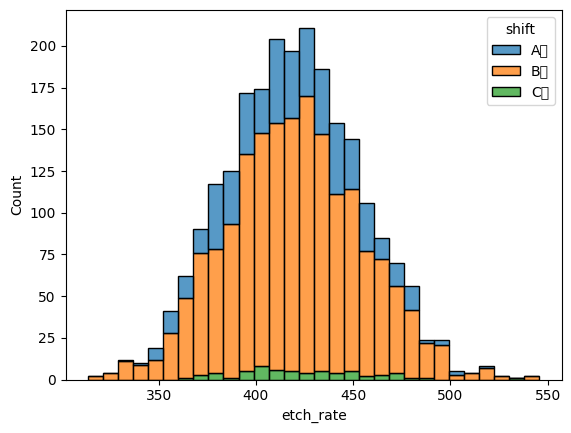

In [10]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.histplot(data=df, x='etch_rate', hue='shift', bins=30, multiple='stack')
plt.show()

In [11]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'bins'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

수치형 변수의 분포를 그룹별로 나누어 히스토그램으로 그립니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.histplot`. 정답은 4글자이고 첫 글자는 `b` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='etch_rate', hue='shift', bi__=30, multiple='stack')
plt.show()

정답04 = 'bi__'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 그래프로 확인한 결과, 챔버 온도(℃)(chamber_temp) 컬럼에서 이상치가 발견되었습니다. AI모델링할 때 부정적 영향이 없도록 아래 가이드에 따라 이상치를 처리하십시오.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, drop, reset_index) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 대상 데이터프레임 : df
- 챔버 온도(℃)(chamber_temp)이(가) upper fence 값보다 크거나 lower fence 값보다 작은 이상치 행(row)을 삭제하세요 (IQR 기준 K=1.5)
- AI모델링에 불필요한 표본 식별번호(sample_id) 컬럼을 삭제하세요
- 전처리를 적용한 데이터프레임은 df_temp 라는 변수명으로 보관하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [17]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

q1 = df['chamber_temp'].quantile(0.25)
q3 = df['chamber_temp'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

df_temp = df.drop( df[(df['chamber_temp'] > upper_fence) | (df['chamber_temp'] < lower_fence)].index, axis=0)
df_temp = df_temp.drop(columns=['sample_id'])
df_temp.reset_index(drop=True, inplace=True)

In [18]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'drop'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 행이나 열을 삭제하는 DataFrame 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `drop`, `quantile`, `reset_index`. 정답은 4글자이고 첫 글자는 `d` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = df['chamber_temp'].quantile(0.25)
q3 = df['chamber_temp'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

df_temp = df.dr__( df[(df['chamber_temp'] > upper_fence) | (df['chamber_temp'] < lower_fence)].index, axis=0)
df_temp = df_temp.drop(columns=['sample_id'])
df_temp.reset_index(drop=True, inplace=True)

정답05 = 'dr__'   # 빈칸에 넣은 단어
```

</details>

### **6. 제시된 가이드에 맞춰 결측치를 처리하고 검증하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_temp`
- 코드의 오류를 바로잡으세요
    - 대상 데이터프레임 : df_temp
    - 결측치 개수를 확인한 뒤, 결측치가 있는 행을 모두 삭제해 df_na 에 보관하세요
    - 처리 후 결측치가 사라졌는지 확인하세요
- **[정답06]** 처리 전 df_temp 의 결측치는 총 몇 개입니까?
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [19]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

print('결측치 처리 전\n', df_temp.isnull().sum())
df_na = df_temp.dropna()
print('결측치 처리 후\n', df_na.isnull().sum())

결측치 처리 전
 etch_rate           0
chamber_temp        0
pressure_mtorr      0
wafer_thk           0
rf_power            0
particle_cnt      115
cd_nm               0
cycle_time_min      0
vacuum_leak         0
chamber             0
shift               0
recipe              0
yield_pct           0
dtype: int64
결측치 처리 후
 etch_rate         0
chamber_temp      0
pressure_mtorr    0
wafer_thk         0
rf_power          0
particle_cnt      0
cd_nm             0
cycle_time_min    0
vacuum_leak       0
chamber           0
shift             0
recipe            0
yield_pct         0
dtype: int64


In [20]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 115

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치 확인 -> 삭제 -> 재확인 순서로 코드를 읽어 보세요. 결측치 처리 전 데이터프레임의 결측치 합계를 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
print('결측치 처리 전\n', df_temp.isnull().sum())
df_na = df_temp.dropna()
print('결측치 처리 후\n', df_na.isnull().sum())

# [정답06] 실행한 결과를 입력하세요
df_temp.isnull().sum().sum()
```

</details>

### **7. 원-핫 인코딩은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 다음 지침에 따라 범주형 데이터를 변환하는 코드를 수정하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 6번 `df_na`
- 제시된 가이드에 맞춰 인코딩하는데 오류가 발생하고 있습니다. 코드의 오류를 바로잡으세요
    - 대상 데이터프레임 : df_na
    - 문자열(범주형) 컬럼 chamber, shift, recipe 을(를) get_dummies 로 인코딩하세요 (타깃 yield_pct 은 제외, drop_first=True)
    - 인코딩된 데이터프레임은 df_enc 에 저장하고 info() 로 구조를 확인하세요
- **[정답07]** 인코딩 후 df_enc 의 **전체 컬럼 개수**는 몇 개인가요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [21]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_enc = pd.get_dummies(data=df_na, columns=['chamber', 'shift', 'recipe'], drop_first=True)
df_enc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2149 entries, 0 to 2263
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   etch_rate       2149 non-null   float64
 1   chamber_temp    2149 non-null   float64
 2   pressure_mtorr  2149 non-null   float64
 3   wafer_thk       2149 non-null   float64
 4   rf_power        2149 non-null   float64
 5   particle_cnt    2149 non-null   float64
 6   cd_nm           2149 non-null   float64
 7   cycle_time_min  2149 non-null   float64
 8   vacuum_leak     2149 non-null   float64
 9   yield_pct       2149 non-null   float64
 10  chamber_C2      2149 non-null   bool   
 11  chamber_C3      2149 non-null   bool   
 12  chamber_C4      2149 non-null   bool   
 13  chamber_C5      2149 non-null   bool   
 14  shift_B조        2149 non-null   bool   
 15  shift_C조        2149 non-null   bool   
 16  recipe_R-02     2149 non-null   bool   
 17  recipe_R-03     2149 non-null   bool  

In [22]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = 18

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

get_dummies 호출의 인자 이름을 점검하세요. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_enc = pd.get_dummies(data=df_na, columns=['chamber', 'shift', 'recipe'], drop_first=True)
df_enc.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_enc.shape[__]
```

</details>

### **8. 모델링 후에 모델의 성능을 평가할 수 있도록 훈련과 검증 각각에 사용할 데이터셋을 분리하려고 합니다. 제시된 가이드에 맞춰 분리하세요.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `df_enc`
- 대상 데이터프레임 : df_enc
- 예측 대상인 수율(%)(yield_pct) 컬럼은 y 에, 그 밖의 컬럼은 X 에 담으세요
- 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요
- 결과를 재현할 수 있게 random_state 값을 7 로 지정하세요 / 훈련과 검증 데이터셋 분리 — 훈련 : 검증 = 75:25 (test_size=0.25)
- train_test_split 함수(scikit-learn)로 나누세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [23]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = df_enc.drop('yield_pct', axis=1)
y = df_enc['yield_pct']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=7)

In [24]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'test_size'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 9글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = df_enc.drop('yield_pct', axis=1)
y = df_enc['yield_pct']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_____=0.25, random_state=7)

정답08 = 'test_____'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 안내대로 스케일링 처리하는데 실행 중 예외가 발생합니다. 코드의 오류를 정정하세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 scaler 변수에 지정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 보관하세요
- **[정답09]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최댓값**을 소수점 둘째 자리까지 기입하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [25]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
print(X_valid.max())

5.832815712024064


In [26]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = 5.83

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최댓값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.max`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.max(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 수율(%)(yield_pct)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LinearRegression와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LinearRegression, fit, RandomForestRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LinearRegression 모델을 아래와 같이 만들어 `lin` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : 지정하지 않음(기본값)
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=100, max_depth=6
    - 난수 시드(random_state) : 2024
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `lin`(LinearRegression) 의 절편(`intercept_`)을 소수점 둘째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [27]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=2024)
rf.fit(X_train, y_train)

round(lin.intercept_, 2)


np.float64(91.56)

In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [28]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 91.56

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 선형 모델은 학습 후 intercept_ 속성에 절편을 저장합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LinearRegression`, `fit`, `RandomForestRegressor`, `intercept_`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=2024)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(lin.intercept_, __)
```

</details>

### **11. 선형회귀 모델의 계수 크기로 어떤 변수가 예측에 큰 영향을 주는지 해석하려 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(sort_values, Series, columns) · NumPy(abs) · scikit-learn(coef_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `np` · 2번 `pd` · 8번 `X` · 10번 `lin`
- 학습된 lin 의 계수(`coef_`)의 **절댓값**을 변수명(X.columns)과 매핑한 Series 로 만들어 내림차순 정렬한 뒤 `coef_s` 에 보관하세요
- **[정답11]** 계수 절댓값이 **가장 큰 변수명**을 쓰세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [29]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd
import numpy as np

coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)
print(coef_s)


vacuum_leak       5.425946
particle_cnt      2.740713
chamber_temp      1.252530
rf_power          0.939471
recipe_R-03       0.389111
recipe_R-02       0.249297
wafer_thk         0.219964
chamber_C5        0.196378
cycle_time_min    0.124856
shift_C조          0.123062
pressure_mtorr    0.111449
shift_B조          0.109025
etch_rate         0.098902
chamber_C2        0.070858
cd_nm             0.045515
chamber_C3        0.035888
chamber_C4        0.008993
dtype: float64


In [30]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'vacuum_leak'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

학습된 계수의 절댓값을 변수명과 묶어 정렬합니다. coef_s 의 첫 번째 인덱스를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `coef_`, `np.abs`, `sort_values`, `index`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import numpy as np

coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
coef_s.index[__]
```

</details>

### **12. 앞서 학습시킨 LinearRegression와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, mean_absolute_error) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `lin`, `rf`
- 다음 지침에 따라 각 모델의 MAE(평균절대오차) 를 산출하려는데 오류가 발생하고 있습니다. 코드의 오류를 정정하세요
    - 앞서 학습시킨 lin 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 MAE(평균절대오차) 값을 각각 linreg_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 MAE(평균절대오차) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (LinearRegression / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [31]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import mean_absolute_error

y_pred_linreg = lin.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

linreg_score = mean_absolute_error(y_valid, y_pred_linreg)
rf_score = mean_absolute_error(y_valid, y_pred_rf)
print(linreg_score, rf_score)

5.141426746651134 5.3029011834198405


In [32]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'LinearRegression'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

MAE(평균절대오차) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 작을수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import mean_absolute_error

y_pred_linreg = lin.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

linreg_score = mean_absolute_error(y_valid, y_pred_linreg)
rf_score = mean_absolute_error(y_valid, y_pred_rf)
print(linreg_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(linreg_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [33]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(7)

### **13. 수율(%)(yield_pct)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 조건대로 모델을 만들고 학습시키세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- TensorFlow(Keras) 로 구현하세요
- 은닉층 구성 : Dense × 2 (노드 [16, 8]), activation='relu'
- 은닉층마다 뒤에 Dropout(0.3) 을 붙이세요
- 조기 종료 : EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True) 를 만들어 estop 에 저장하세요
- 출력층은 노드 1개이고 활성화 함수는 지정하지 않습니다(회귀)
- compile 설정 : optimizer='adam', loss='mse', metrics=[mae]
- batch_size 는 16, epochs 는 30 로 학습하고 학습정보는 history 변수에 담으세요 (검증 데이터: X_valid, 검증 레이블), 학습 진행 로그는 출력하지 않도록 verbose=0 으로 설정하세요
- 가이드에 없는 인자는 추가하지 말고 기본값으로 두세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [34]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(16, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(8, activation='relu'),
    Dropout(0.3),
    Dense(1)
])

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    verbose=0,
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [35]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'mse'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 예측과 정답의 차이를 재는 손실 함수의 이름입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 3글자이고 첫 글자는 `m` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(16, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(8, activation='relu'),
    Dropout(0.3),
    Dense(1)
])

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='ms_', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    verbose=0,
                    callbacks=cb_list)

정답13 = 'ms_'   # 빈칸에 넣은 단어
```

</details>

### **14. 학습이 끝난 모델의 최종 성능을 검증 데이터로 한 번 더 확인하고자 합니다.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: TensorFlow(Keras)(evaluate) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 13번 `model`
- 학습된 `model` 의 `evaluate` 로 검증 데이터(X_valid, y_valid)의 성능을 산출하세요 (verbose=0)
    - 반환되는 값은 loss 와 compile 에서 지정한 metrics(mae) 순서입니다. 각각 `loss, mae` 변수에 보관하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [36]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

loss, mae = model.evaluate(X_valid, y_valid, verbose=0)

In [37]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'verbose'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

학습된 모델에 검증 데이터를 넣어 손실과 지표를 한 번에 구합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `model.evaluate`. 정답은 7글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
loss, mae = model.evaluate(X_valid, y_valid, verb___=0)

정답14 = 'verb___'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.